# 11. Second-Order Systems

*Physical Modeling in MATLAB* by Allen B. Downey. Run each code cell in order with Shift+Enter; you can change the code and run it again.

So far we’ve seen first-order differential equations and systems of first-order ODEs. In this chapter, we’ll introduce second-order systems, which are particularly useful for modeling Newtonian motion.

## Newtonian Motion

Newton’s second law of motion is often written like this:

$$F = m a$$ where $F$ is the net force acting on an object, $m$ is the mass of the object, and $a$ is the acceleration of the object.

This equation suggests that if you know $m$ and $a$, you can compute the force. And that’s true, but in most physical simulations it’s the other way around: based on a physical model, you know $F$ and $m$, and you compute $a$.

So if we know acceleration as a function of time, how do we find the position of the object, $r$? Well, we know that acceleration is the second derivative of position, so we can write the differential equation

$$\frac{d^2r}{dt^2} = a$$ where ${d^2r}/{dt^2}$ is the second time derivative of $r$.

Because this equation includes a second derivative, it’s a second-order ODE. We can’t solve the equation using `ode45` in this form, but by introducing a new variable, *v*, for velocity, we can rewrite it as a system of first-order ODEs:

$$\begin{aligned}
    \frac{dr}{dt} &= v   \\
    \frac{dv}{dt} &= a
\end{aligned}$$

The first equation says that the first derivative of $r$ is $v$; the second equation says that the first derivative of $v$ is $a$.

## Free Fall

As an example of Newtonian motion, let’s go back to the question from Exercise 1.1:

> If you drop a penny from the top of the Empire State Building, how long does it take to reach the sidewalk, and how fast is it going when it gets there?

We’ll start with no air resistance; then we’ll add air resistance to the model and see what effect it has.

Near the surface of the earth, acceleration due to gravity is -9.8 m/s, where the minus sign indicates that gravity pulls down. If the object falls straight down, we can describe its position with a scalar value $y$, representing altitude.

Listing 11.1 contains a rate function we can use with `ode45` to solve this problem:

*Listing 11.1: A rate function for the falling penny problem*

In [ ]:
function res = rate_func(t, X)
    % unpack position and velocity
    y = X(1);
    v = X(2);

    % compute the derivatives
    dydt = v;
    dvdt = -9.8;

    % pack the derivatives into a column vector
    res = [dydt; dvdt];
end

The rate function in Listing 11.1 takes `t` and `X` as input variables, where the elements of `X` are understood to be the position and velocity of the penny.

It returns a column vector that contains `dydt` and `dvdt`, which are velocity and acceleration, respectively. Since velocity is the second element of `X`, we can simply assign this value to `dydt`. And since the derivative of velocity is acceleration, we can assign the acceleration due to gravity to `dvdt`.

As always, we should test the rate function before we call `ode45`. Here’s the top-level function we can use to test it:

In [ ]:
function penny()
   t = 0;
   X = [381, 0];
   rate_func(t, X)
end

The initial condition of `X` is the initial position, which is the height of the Empire State Building, about 381 m, and the initial velocity, which is 0 m/s.

The result from `rate_func` is

In [ ]:
penny

which is what we expect.

Now we can run `ode45` with this rate function:

In [ ]:
X = [381, 0];    % the initial condition, as in penny
tspan = [0, 10]
[T, M] = ode45(@rate_func, tspan, X)

As always, the first argument is the function handle, the second is the time span (10 seconds), and the third is the initial condition.

The result is a vector, `T`, that contains the time values, and a matrix, `M`, that contains two columns, one for altitude and one for velocity.

We can extract the first column and plot it, like this:

In [ ]:
Y = M(:, 1)
plot(T, Y)

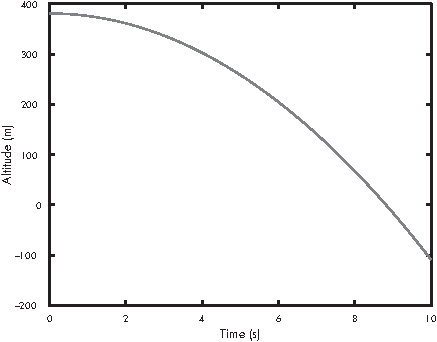

*Figure 11.1: Altitude versus time for an object in free fall*

Figure 11.1 shows the result. Altitude drops slowly at first and picks up speed. Between 8 and 9 seconds, the altitude reaches 0, which means the penny hits the sidewalk. But `ode45` doesn’t know where the ground is, so the penny keeps going through 0 into negative altitude. We’ll solve that problem in the next section.

## ODE Events

Normally when you call `ode45` you specify a start time and an end time. But sometimes you don’t know ahead of time when the simulation should end. To solve this problem we can define an *event*, something of interest that happens during a simulation, like the penny reaching the ground.

Here are the steps:

1.  First we define an *event function* that allows `ode45` to figure out when an event occurs. Here’s an event function for the penny example:

In [ ]:
function [value, isterminal, direction] = event_func(t,X)
    value = X(1);
    isterminal = 1;
    direction = -1;
end

2.  Next, we use `odeset` to create an object called `options`:

In [ ]:
options = odeset('Events', @event_func);

3.  Finally, we pass `options` as a fourth argument to `ode45`:

In [ ]:
[T, M] = ode45(@rate_func, tspan, X, options);

::: enumerate
When `ode45` runs, it invokes `event_func` after each time step. If the event function indicates that a terminal event occurred, `ode45` stops the simulation.
:::

Let’s look at the results from the penny example:

In [ ]:
T(end)
M(end, :)

The last value of `T` is about 8.8, which is the number of seconds the penny takes to reach the sidewalk.

The last row of `M` indicates that the final altitude is 0, which is what we wanted, and the final velocity is about -86 m/s.

## Air Resistance

To make this simulation more realistic, we can add air resistance. For large objects moving quickly through air, the force due to air resistance, called *drag*, is proportional to velocity squared. For an object falling down, drag is directed up, so if velocity is negative, drag force is positive.

Here’s how we can compute the force of drag as a function of velocity in one dimension:

$$f_\mathrm{d} = -\mathrm{sign}(v) b v^2$$ where $v$ is velocity and $b$ is a drag constant that depends on the density of air, the cross-sectional area of the object, and the shape of the object.

The sign or signum function returns the value $1$ for positive values of $v$ and $-1$ for negative values. So $f_\mathrm{d}$ is always in the opposite direction of $v$.

To convert from force to acceleration we have to know mass, but that’s easy to find: the mass of a penny is about 2.5 . It’s not as easy to find the drag constant, but based on reports that the terminal velocity of a penny is about 18 m/s, I’ve estimated that it’s about 75e-6 kg/m.

Listing 11.2 defines a function that takes `t` and `X` as input variables and returns the total acceleration of the penny due to gravity and drag:

*Listing 11.2: Calculating acceleration of a penny with drag*

In [ ]:
function res = acceleration(t, X)
    b = 75e-6;                 % drag constant in kg/m
    v = X(2);                  % velocity in m/s
    f_d = -sign(v) * b * v^2;  % drag force in N

    m = 2.5e-3;               % mass in kg
    a_d = f_d / m;            % drag acceleration in m/s^2

    a_g = -9.8;               % acceleration of gravity in m/s^2
    res = a_g + a_d;          % total acceleration
end

First, we compute force due to drag . Then we compute acceleration due to drag . Lastly, we compute total acceleration due to drag and gravity.

Be careful when you’re working with forces and accelerations; make sure you only add forces to forces or accelerations to accelerations. In my code, I use comments to remind myself what units the values have. That helps me avoid errors like adding forces to accelerations.

To use this function, we make a small change in `rate_func`:

In [ ]:
function res = rate_func(t, X)
    y = X(1);
    v = X(2);

    dydt = v;
    dvdt = acceleration(t, X);   % this line has changed

    res = [dydt; dvdt];
end

In [ ]:
% Run the simulation again with drag (Figure 11.2). The penny takes longer
% to reach the ground, so the time span is longer.
tspan = [0, 30];
[T, M] = ode45(@rate_func, tspan, X, options);
plot(T, M(:, 1))
xlabel('Time (s)')
ylabel('Altitude (m)')
T(end)
M(end, :)

In the previous version, `dvdt` is always `-9.8`, the acceleration due to gravity. In this version, we call `acceleration` to compute the total acceleration due to gravity and drag .

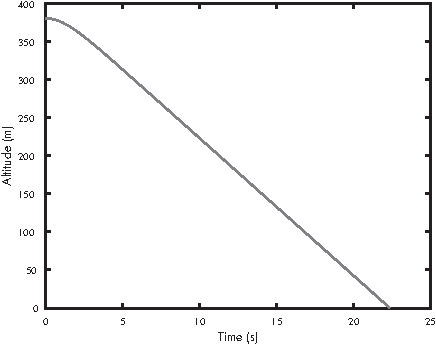

*Figure 11.2: Altitude versus time for a penny in free fall with air resistance*

Everything else is the same. Figure 11.2 shows the result.

Air resistance makes a big difference! Velocity increases until acceleration due to drag equals acceleration due to gravity; after that, velocity is constant and position decreases linearly (and much more slowly than it would in a vacuum).

With air resistance, the time until the penny hits the sidewalk is 22.4 s, substantially longer than before (8.8 s).

And the final velocity is 18.1 m/s, substantially slower than before (86 m/s).

## Chapter Review

In this chapter, we used Newton’s laws of motion to write a differential equation that describes the motion of a falling penny.

We rewrote that equation as a system of first-order differential equations so we could use `ode45` to solve it. Then we ran simulations of a falling penny with and without air resistance, also known as *drag*.

We defined an *event* as something of interest that happens during a simulation, like a collision between moving objects, and we wrote an *event function*, which allows `ode45` to figure out when an event occurs.

In the next chapter, we extend Newtonian motion to two dimensions and model the flight of a baseball.

## Exercises

Before you go on, you might want to work on the following exercise.

**Exercise.**

In this exercise we’ll model the descent of a skydiver, taking into account the change in drag when the parachute opens.

1.  Modify the penny code from this chapter to simulate the descent of a 75 kg skydiver from an initial altitude of 4000 m. The drag constant for a skydiver without a parachute is about 0.2 kg/m. What would the velocity of the skydiver be on impact?

2.  After opening their parachute, the velocity of the skydiver slows to about 5 m/s. Use your simulation to find the drag constant that yields a terminal velocity of 5 m/s.

3.  Increase the mass of the skydiver, and confirm that terminal velocity increases. This phenomenon is the source of the intuition that heavy objects fall faster; in air, they do!

4.  Now suppose the skydiver free falls until they get to an altitude of 1000 m before opening the parachute. How long would it take them to reach the ground?

5.  What is the lowest altitude where the skydiver can open the parachute and still land at less than 6 m/s (assuming that the parachute opens and deploys instantly)?

**Exercise.**

Here’s a question from the website *Ask an Astronomer* (see <https://greenteapress.com/matlab/astro>):

> If the Earth suddenly stopped orbiting the Sun, I know eventually it would be pulled in by the Sun’s gravity and hit it. How long would it take the Earth to hit the Sun? I imagine it would go slowly at first and then pick up speed.

Use `ode45` to answer this question. Here are some suggestions about how to proceed:

1.  Look up the Law of Universal Gravitation and any constants you need. I suggest you work entirely in SI units: meters, kilograms, and newtons.

2.  When the distance between the Earth and the Sun gets small, this system behaves badly, so you should use an event function to stop when the surface of the Earth reaches the surface of the Sun.

3.  Express your answer in days, and plot the results as millions of kilometers versus days.

In [ ]:
% Solution

% Simulate the descent of a skydiver who opens the parachute at altitude
% h_open (default 1000 m).  The lowest altitude where they still land at
% less than 6 m/s is about 8 m (the last part of the exercise).

function skydiver(h_open)
    if nargin < 1
        h_open = 1000;        % altitude where the parachute opens, in m
    end
    t = 0;
    X = [4000, 0];
    rate_func(t, X, h_open)

    tspan = [0, 1000];
    options = odeset('Events', @event_func);
    [T, M] = ode45(@(t, X) rate_func(t, X, h_open), tspan, X, options);

    Y = M(:, 1);
    V = M(:, 2);

    plot(T, Y)
    xlabel('Time (s)')
    ylabel('Altitude (m)')

    T(end)
    M(end, :)
end

function res = rate_func(t, X, h_open)
    % unpack position and velocity
    y = X(1);
    v = X(2);

    % compute the derivatives
    dydt = v;
    dvdt = acceleration(t, X, h_open);

    % pack the derivatives into a column vector
    res = [dydt; dvdt];
end

function res = acceleration(t, X, h_open)
    b_free = 0.2;             % drag constant in kg/m
    b_parachute = 29;

    y = X(1);
    if y < h_open
        b = b_parachute;
    else
        b = b_free;
    end

    v = X(2);                 % velocity in m/s
    f_d = -sign(v) * b * v^2; % drag force in N

    m = 75;                   % mass in kg
    a_d = f_d / m;            % drag acceleration in m/s^2

    a_g = -9.8;               % acceleration due to gravity in m/s^2
    res = a_g + a_d;          % total acceleration
end

function [value, isterminal, direction] = event_func(t,X)
    value = X(1);
    isterminal = 1;
    direction = -1;
end

In [ ]:
% Solution

skydiver

In [ ]:
% Solution

% Simulate the Earth falling into the Sun.

function earth()
    y0 = 150e9;           % meters
    t_end = 1e7;          % seconds
    
    t = 0;
    X = [y0, 0];
    rate_func(t, X)
   
    tspan = [0, t_end];
    options = odeset('Events', @event_func);
    [T, M] = ode45(@rate_func, tspan, X, options);
    
    % convert time to days
    % convert distance to millions of km
    T = T / 60 / 60 / 24;
    Y = M(:, 1) / 1e9;
    
    plot(T, Y)
    xlabel('Time (days)')
    ylabel('Distance from sun (million km)')
    
    T(end)
    M(end, :)
end

function res = rate_func(t, X)
    % unpack position and velocity
    y = X(1);      
    v = X(2);      
    
    % compute the derivatives
    dydt = v;
    dvdt = acceleration(t, X);

    % pack the derivatives into a column vector
    res = [dydt; dvdt];
end

function res = acceleration(t, X)
    G=6.674e-11;          % N / kg^2 * m^2,
    m_sun = 1.989e30;     %  kg,
    m_earth = 5.972e24;   % kg,

    y = X(1);
    f_g = -G * m_earth * m_sun / y^2;
    a_g = f_g / m_earth;
    res = a_g;
end

function [value, isterminal, direction] = event_func(t, X)
    r_earth = 6.371e6;           % meters
    r_sun = 695.508e6;           % meters
    y_final = r_sun + r_earth;
    y = X(1);
    
    value = y - y_final;
    isterminal = 1;
    direction = -1;
end

In [ ]:
% Solution

earth